<a href="https://colab.research.google.com/github/IvanovaKaryna/-/blob/main/%D0%9B%D0%A08_%D0%86%D0%B2%D0%B0%D0%BD%D0%BE%D0%B2%D0%B0_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:
iris = load_iris()
iris_df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

X_iris = iris_df.iloc[:, :3]
display(X_iris.head())

,sepal length (cm),sepal width (cm),petal length (cm)
0,5.1,3.5,1.4
1,4.9,3.0,1.4
2,4.7,3.2,1.3
3,4.6,3.1,1.5
4,5.0,3.6,1.4


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

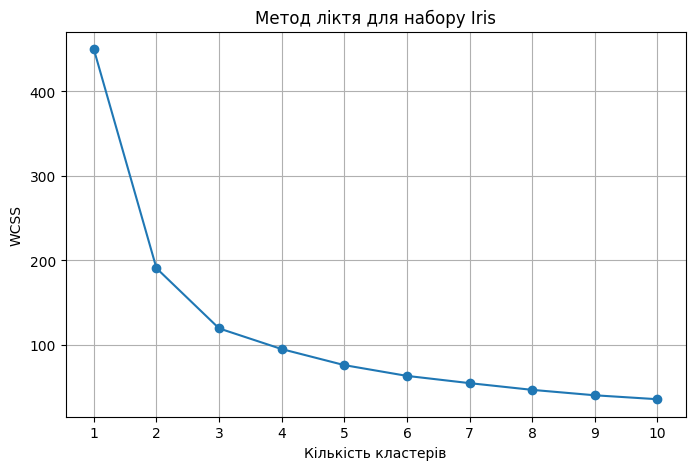

In [3]:
scaler = StandardScaler()
X_iris_scaled = scaler.fit_transform(X_iris)
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_iris_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Кількість кластерів')
plt.ylabel('WCSS')
plt.title('Метод ліктя для набору Iris')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

,Кількість кластерів,Коефіцієнт силуета
0,2,0.5525
1,3,0.4594
2,4,0.4057
3,5,0.3755
4,6,0.3772
5,7,0.3628
6,8,0.3814
7,9,0.3749
8,10,0.3791


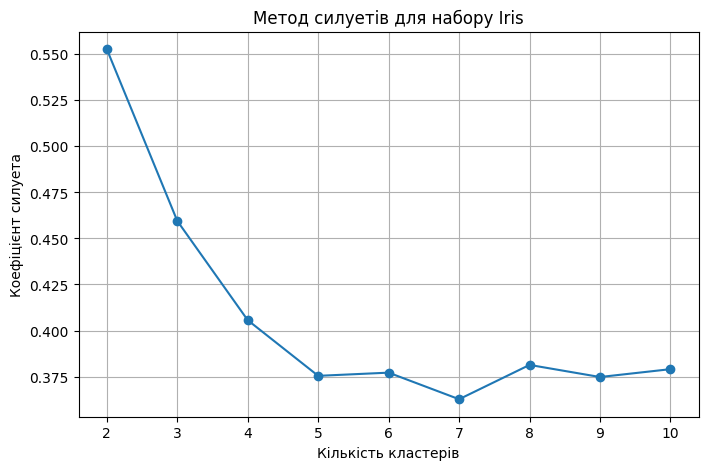

In [4]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_iris_scaled)

    score = silhouette_score(X_iris_scaled, labels)
    silhouette_scores.append(score)

silhouette_df = pd.DataFrame({
    'Кількість кластерів': range(2, 11),
    'Коефіцієнт силуета': silhouette_scores
})

display(silhouette_df.round(4))

plt.figure(figsize=(8, 5))
plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)
plt.xlabel('Кількість кластерів')
plt.ylabel('Коефіцієнт силуета')
plt.title('Метод силуетів для набору Iris')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

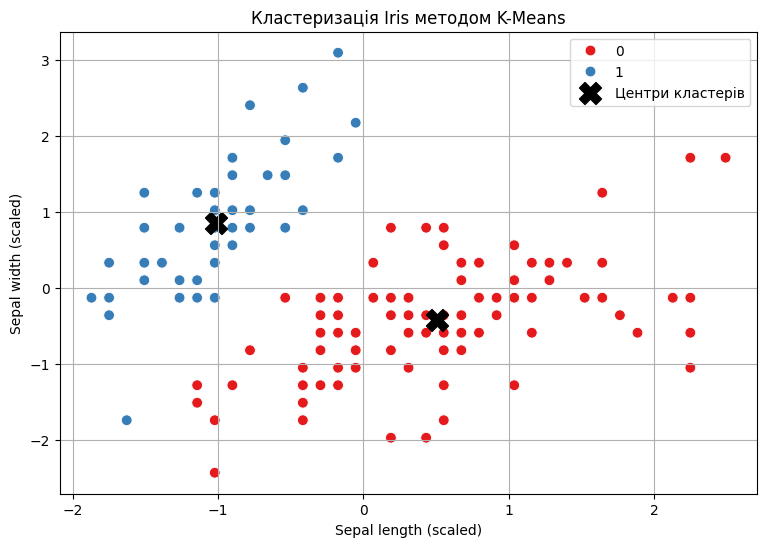

In [5]:
kmeans_iris = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

iris_clusters = kmeans_iris.fit_predict(X_iris_scaled)

iris_df['Cluster'] = iris_clusters

centers = kmeans_iris.cluster_centers_

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_iris_scaled[:, 0],
    y=X_iris_scaled[:, 1],
    hue=iris_clusters,
    palette='Set1',
    s=60
)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker='X',
    s=250,
    color='black',
    label='Центри кластерів'
)

plt.xlabel('Sepal length (scaled)')
plt.ylabel('Sepal width (scaled)')
plt.title('Кластеризація Iris методом K-Means')
plt.legend()
plt.grid(True)
plt.show()

### Висновок до завдання 1

Під час виконання першого завдання я застосувала алгоритм K-Means для кластеризації набору даних Iris. Для визначення оптимальної кількості кластерів було використано метод ліктя та коефіцієнт силуета. Метод ліктя допоміг оцінити зміну внутрішньокластерної суми квадратів, а метод силуетів якість розподілу об'єктів між кластерами. Для фінальної кластеризації було обрано два кластери відповідно до умови завдання. Результати були представлені на графіку з відображенням центрів кластерів. Отримані графіки дали змогу порівняти різні підходи до визначення кількості кластерів.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, classification_report

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [7]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [8]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [9]:
print("Назви стовпців:")
print(df.columns.tolist())

Назви стовпців:
['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [11]:
print("Кількість пропущених значень:")
print(df.isnull().sum())

Кількість пропущених значень:
StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [12]:
print("Кількість дублікатів:", df.duplicated().sum())

Кількість дублікатів: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [13]:
display(df.describe(include='all'))

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [14]:
X = df.drop(columns=['GradeClass', 'StudentID'])
y = df['GradeClass']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Розмір X_train:", X_train_scaled.shape)
print("Розмір X_test:", X_test_scaled.shape)
print("Розмір y_train:", y_train.shape)
print("Розмір y_test:", y_test.shape)

Розмір X_train: (1913, 13)
Розмір X_test: (479, 13)
Розмір y_train: (1913,)
Розмір y_test: (479,)


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [15]:
rf = RandomForestClassifier(random_state=42)
rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

rf_grid = GridSearchCV(
    rf,
    rf_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

rf_grid.fit(X_train_scaled, y_train)

print("Найкращі параметри:", rf_grid.best_params_)
print("Середня CV accuracy:", round(rf_grid.best_score_, 4))

rf_pred = rf_grid.predict(X_test_scaled)

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Тестова accuracy:", round(rf_accuracy, 4))

Найкращі параметри: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Середня CV accuracy: 0.9211
Тестова accuracy: 0.9102


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [16]:
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        solver='saga',
        max_iter=5000,
        random_state=42
    ))
])

lr_params = {
    'model__C': [0.01, 0.1, 1, 10],
    'model__penalty': ['l1', 'l2']
}

lr_grid = GridSearchCV(
    lr_pipeline,
    lr_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

lr_grid.fit(X_train, y_train)

print("Найкращі параметри:", lr_grid.best_params_)
print("Середня CV accuracy:", round(lr_grid.best_score_, 4))

lr_pred = lr_grid.predict(X_test)

lr_accuracy = accuracy_score(y_test, lr_pred)

print("Тестова accuracy:", round(lr_accuracy, 4))

Найкращі параметри: {'model__C': 0.1, 'model__penalty': 'l1'}
Середня CV accuracy: 0.8024
Тестова accuracy: 0.8184


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [17]:
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVC())
])

svm_params = {
    'model__C': [0.1, 1, 10],
    'model__kernel': ['linear', 'rbf'],
    'model__gamma': ['scale', 'auto']
}

svm_grid = GridSearchCV(
    svm_pipeline,
    svm_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

svm_grid.fit(X_train, y_train)

print("Найкращі параметри:", svm_grid.best_params_)
print("Середня CV accuracy:", round(svm_grid.best_score_, 4))

svm_pred = svm_grid.predict(X_test)

svm_accuracy = accuracy_score(y_test, svm_pred)

print("Тестова accuracy:", round(svm_accuracy, 4))

Найкращі параметри: {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Середня CV accuracy: 0.8521
Тестова accuracy: 0.858


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [18]:
comparison = pd.DataFrame({
    'Модель': [
        'Random Forest',
        'Logistic Regression',
        'SVM'
    ],
    'CV Accuracy': [
        rf_grid.best_score_,
        lr_grid.best_score_,
        svm_grid.best_score_
    ],
    'Test Accuracy': [
        rf_accuracy,
        lr_accuracy,
        svm_accuracy
    ]
})

display(comparison.round(4))

best_grid = max(
    [rf_grid, lr_grid, svm_grid],
    key=lambda model: model.best_score_
)

print("Найкраща модель за CV accuracy:")
print(best_grid.best_estimator_)

best_predictions = best_grid.predict(X_test)

print("\nClassification report:")
print(classification_report(
    y_test,
    best_predictions,
    zero_division=0
))

,Модель,CV Accuracy,Test Accuracy
0,Random Forest,0.9211,0.9102
1,Logistic Regression,0.8024,0.8184
2,SVM,0.8521,0.8580


Найкраща модель за CV accuracy:
RandomForestClassifier(max_depth=10, n_estimators=200, random_state=42)

Classification report:
              precision    recall  f1-score   support

         0.0       0.00      0.00      0.00        21
         1.0       0.09      0.02      0.03        54
         2.0       0.06      0.08      0.07        78
         3.0       0.21      0.90      0.34        83
         4.0       0.57      0.02      0.03       243

    accuracy                           0.18       479
   macro avg       0.19      0.20      0.09       479
weighted avg       0.35      0.18      0.09       479



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

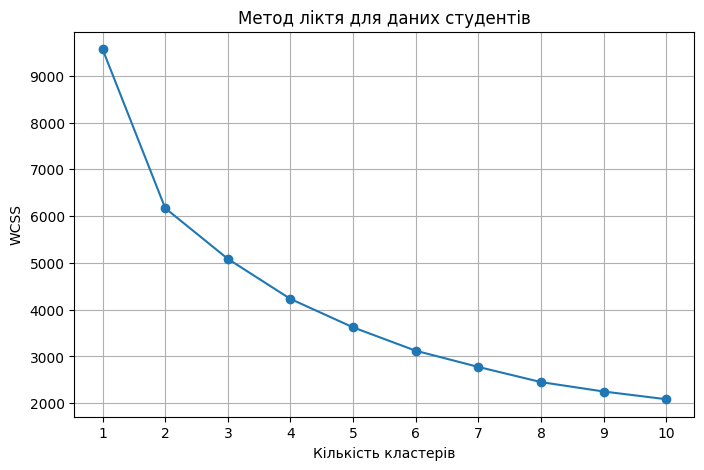

In [19]:
student_features = df[
    ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
]

student_scaler = StandardScaler()
X_students_scaled = student_scaler.fit_transform(student_features)

student_wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_students_scaled)
    student_wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), student_wcss, marker='o')
plt.xlabel('Кількість кластерів')
plt.ylabel('WCSS')
plt.title('Метод ліктя для даних студентів')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

,Кількість кластерів,Коефіцієнт силуета
0,2,0.3080
1,3,0.2702
2,4,0.2580
3,5,0.2645
4,6,0.2689
5,7,0.2692
6,8,0.2712
7,9,0.2732
8,10,0.2725


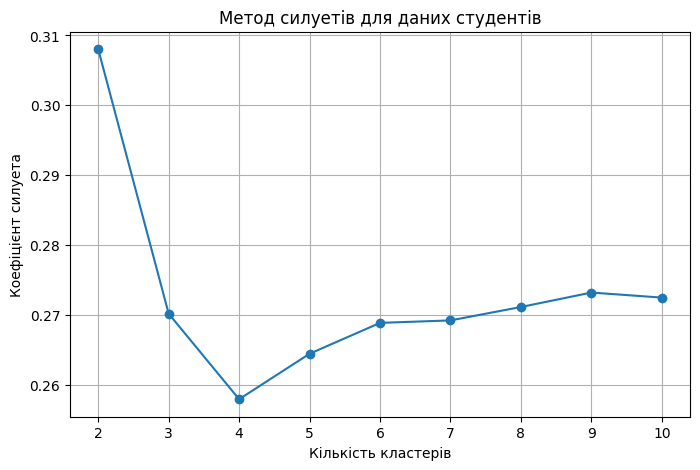

In [20]:
student_silhouette = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_students_scaled)

    score = silhouette_score(X_students_scaled, labels)
    student_silhouette.append(score)

student_silhouette_df = pd.DataFrame({
    'Кількість кластерів': range(2, 11),
    'Коефіцієнт силуета': student_silhouette
})

display(student_silhouette_df.round(4))

plt.figure(figsize=(8, 5))
plt.plot(
    range(2, 11),
    student_silhouette,
    marker='o'
)
plt.xlabel('Кількість кластерів')
plt.ylabel('Коефіцієнт силуета')
plt.title('Метод силуетів для даних студентів')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [21]:
!pip install -q kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [22]:
import numpy as np

from sklearn.decomposition import PCA
from kneed import KneeLocator

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [23]:
X_pca = df.drop(
    columns=['StudentID', 'GradeClass']
)

scaler_pca = StandardScaler()
X_pca_scaled = scaler_pca.fit_transform(X_pca)

print("Розмір даних для PCA:", X_pca_scaled.shape)

Розмір даних для PCA: (2392, 13)


**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [24]:
pca = PCA()
pca.fit(X_pca_scaled)

explained_variance = pca.explained_variance_ratio_

print("Частка поясненої дисперсії:")
print(explained_variance)

Частка поясненої дисперсії:
[0.15246911 0.0861136  0.08267885 0.08071826 0.07864825 0.07793075
 0.0763079  0.07600434 0.07440892 0.0737979  0.07167781 0.06746103
 0.00178329]


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

Оптимальна кількість компонент: 2


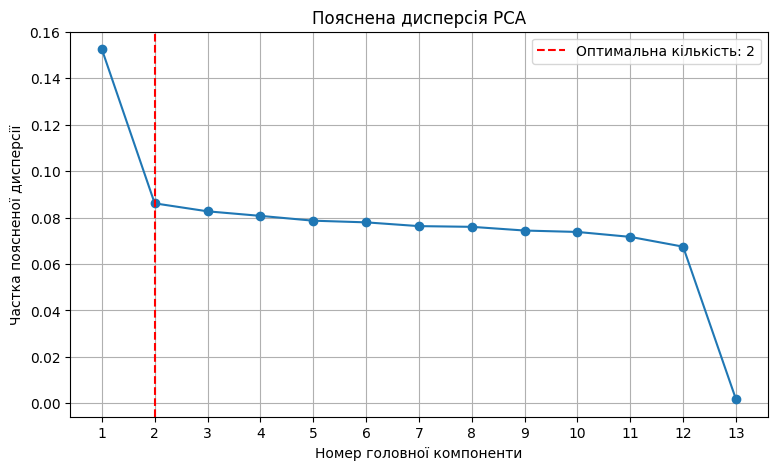

In [25]:

components = np.arange(1, len(explained_variance) + 1)

knee_locator = KneeLocator(
    components,
    explained_variance,
    curve='convex',
    direction='decreasing'
)

optimal_components = knee_locator.knee

print("Оптимальна кількість компонент:", optimal_components)

plt.figure(figsize=(9, 5))
plt.plot(
    components,
    explained_variance,
    marker='o'
)

if optimal_components is not None:
    plt.axvline(
        x=optimal_components,
        color='red',
        linestyle='--',
        label=f'Оптимальна кількість: {optimal_components}'
    )

plt.xlabel('Номер головної компоненти')
plt.ylabel('Частка поясненої дисперсії')
plt.title('Пояснена дисперсія PCA')
plt.xticks(components)
plt.legend()
plt.grid(True)
plt.show()

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

Кількість обраних компонент: 2
Кумулятивна пояснена дисперсія: 0.2386
У відсотках: 23.86 %


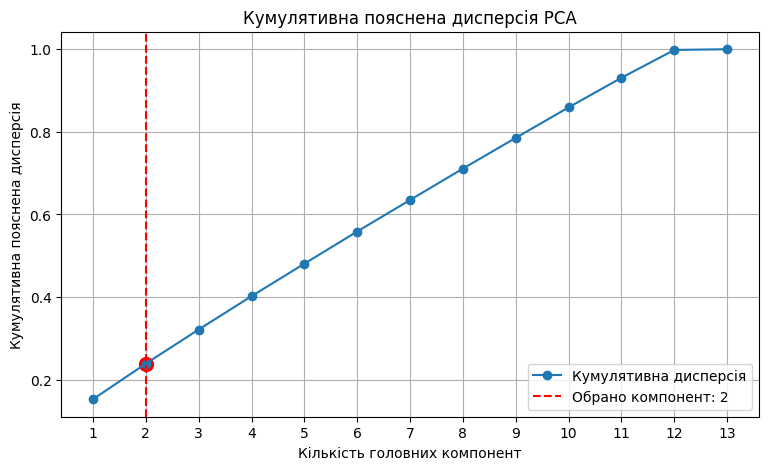

Розмір даних після PCA: (2392, 2)


In [26]:

cumulative_variance = np.cumsum(explained_variance)
if optimal_components is None:
    optimal_components = np.argmax(
        cumulative_variance >= 0.90
    ) + 1

print("Кількість обраних компонент:", optimal_components)

selected_variance = cumulative_variance[optimal_components - 1]

print(
    "Кумулятивна пояснена дисперсія:",
    round(selected_variance, 4)
)
print(
    "У відсотках:",
    round(selected_variance * 100, 2), "%"
)

plt.figure(figsize=(9, 5))

plt.plot(
    components,
    cumulative_variance,
    marker='o',
    label='Кумулятивна дисперсія'
)

plt.axvline(
    x=optimal_components,
    color='red',
    linestyle='--',
    label=f'Обрано компонент: {optimal_components}'
)

plt.scatter(
    optimal_components,
    selected_variance,
    color='red',
    s=100
)

plt.xlabel('Кількість головних компонент')
plt.ylabel('Кумулятивна пояснена дисперсія')
plt.title('Кумулятивна пояснена дисперсія PCA')
plt.xticks(components)
plt.legend()
plt.grid(True)
plt.show()

pca_final = PCA(n_components=optimal_components)
X_pca_transformed = pca_final.fit_transform(X_pca_scaled)

print("Розмір даних після PCA:", X_pca_transformed.shape)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [27]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

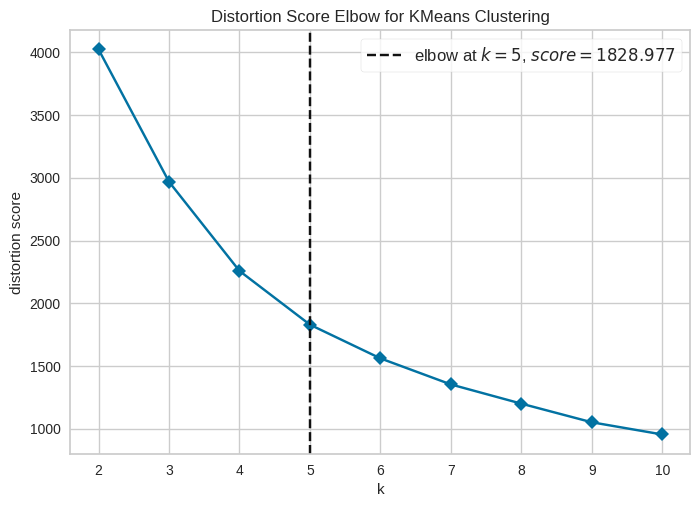

Оптимальна кількість кластерів після PCA: 5


In [28]:

kmeans_pca = KMeans(
    random_state=42,
    n_init=10
)

visualizer = KElbowVisualizer(
    kmeans_pca,
    k=(2, 11),
    metric='distortion',
    timings=False
)

visualizer.fit(X_pca_transformed)

plt.title('Метод ліктя після PCA')
visualizer.show()

print("Оптимальна кількість кластерів після PCA:",
      visualizer.elbow_value_)

## Висновки

## Висновки

Під час виконання лабораторної роботи я ознайомилася з методами кластеризації K-Means, методом ліктя, коефіцієнтом силуета та методом головних компонент PCA.

У першому завданні я виконала кластеризацію набору даних Iris. Найкращий коефіцієнт силуета отримано для двох кластерів - 0.5525.

У другому завданні я дослідила набір даних про студентів, порівняла три моделі класифікації та визначила найкращу за середньою CV accuracy. Найкращий результат показала модель Random Forest із CV accuracy 0.9211 та тестовою accuracy 0.9102.

Також я виконала кластеризацію даних студентів без використання цільової ознаки GradeClass. Найкращий коефіцієнт силуета становив 0.3080 для двох кластерів.

На завершення я застосувала PCA. Було обрано дві головні компоненти, які пояснюють 23.86% дисперсії. Додатково за допомогою Yellowbrick після PCA було визначено п'ять кластерів.

Під час роботи я закріпила навички класифікації, кластеризації, оцінювання якості кластерів та зменшення розмірності даних.